In [29]:
import pandas as pd
import numpy as np

# ---------- 1. Load dataset ----------
df = pd.read_csv("../Dataset/AirQualityUCI.csv", sep=';', decimal=',')

# Remove trailing empty columns (common in UCI file)
df = df.loc[:, ~df.columns.str.fullmatch("")]

print("Initial shape:", df.shape)

Initial shape: (9471, 17)


In [30]:
# ---------- 2. Parse timestamp ----------
def parse_timestamp(date_str, time_str):
    t = str(time_str).replace(".", ":")
    for fmt in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return pd.to_datetime(f"{date_str} {t}", format=fmt)
        except Exception:
            pass
    return pd.NaT

df["timestamp"] = [parse_timestamp(d, t) for d, t in zip(df["Date"], df["Time"])]
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)

In [31]:
# ---------- 3. Replace sentinel (-200) with NaN ----------
for col in df.columns:
    if col not in ["Date", "Time", "timestamp"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(-200, np.nan)

In [32]:
# ---------- 4. Drop columns fully empty or >80% NaN ----------
na_ratio = df.isna().mean()
drop_cols = na_ratio[na_ratio > 0.8].index.tolist()
if drop_cols:
    print("Dropping columns with >80% NaN:", drop_cols)
    df = df.drop(columns=drop_cols)

Dropping columns with >80% NaN: ['NMHC(GT)', 'Unnamed: 15', 'Unnamed: 16']


In [33]:
# ---------- 5. Interpolate numeric columns ----------
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].interpolate(method="linear", limit_direction="both")


In [34]:
# ---------- 6. Verify time continuity ----------
df["diff_hours"] = df["timestamp"].diff().dt.total_seconds() / 3600
discontinuities = df[df["diff_hours"] > 1]
print(f"\nTime discontinuities >1h: {len(discontinuities)}")

# Drop helper
df = df.drop(columns=["diff_hours"], errors="ignore")


Time discontinuities >1h: 0


In [35]:
# ---------- 7. Save cleaned dataset ----------
df.to_csv("../Dataset/AirQuality_clean.csv", index=False)
print("\nSaved cleaned dataset → AirQuality_clean.csv")
print("Cleaned shape:", df.shape)

# ---------- 8. Quick summary ----------
print("\nRemaining NaN counts (after interpolation):")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nDate range:", df["timestamp"].min(), "→", df["timestamp"].max())


Saved cleaned dataset → AirQuality_clean.csv
Cleaned shape: (9357, 15)

Remaining NaN counts (after interpolation):
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
dtype: int64

Date range: 2004-03-10 18:00:00 → 2005-04-04 14:00:00


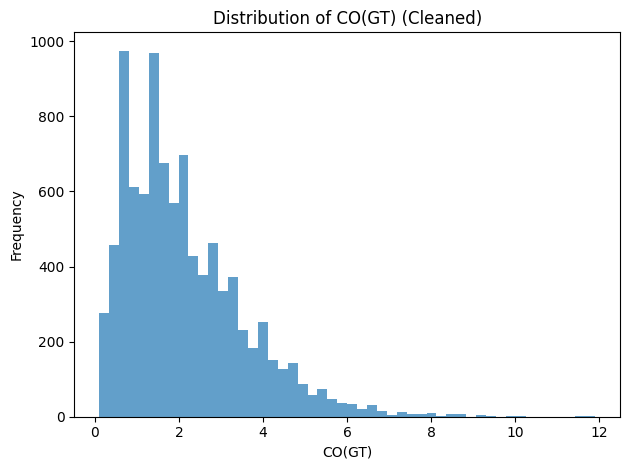

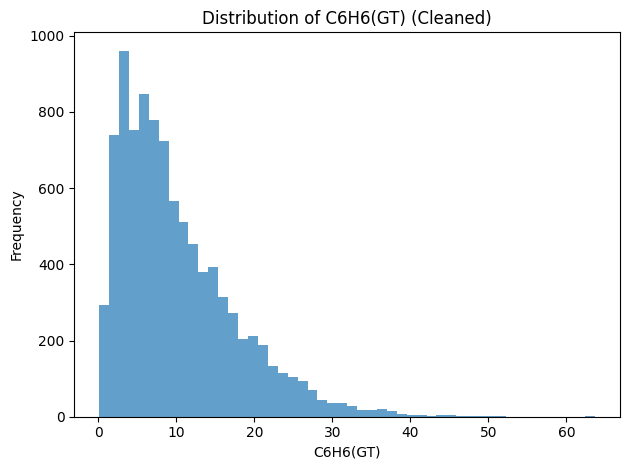

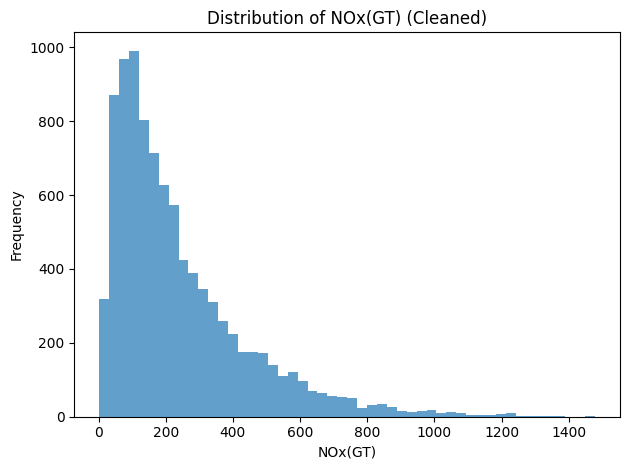

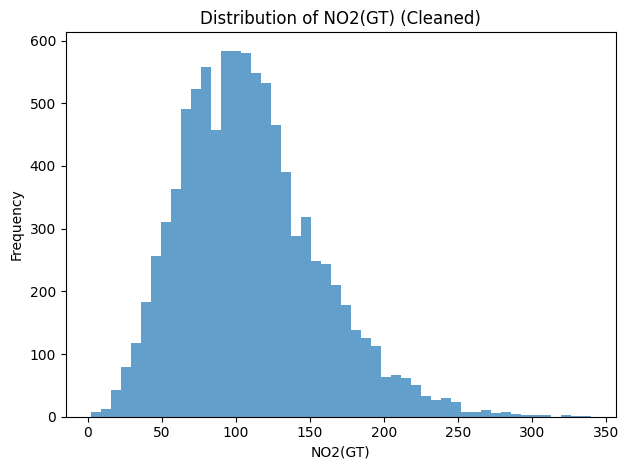

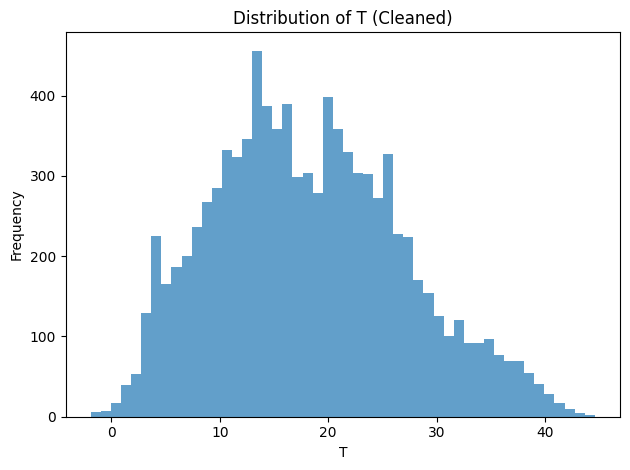

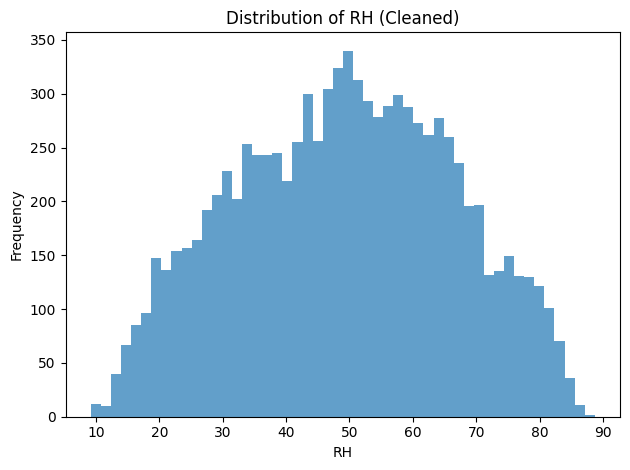

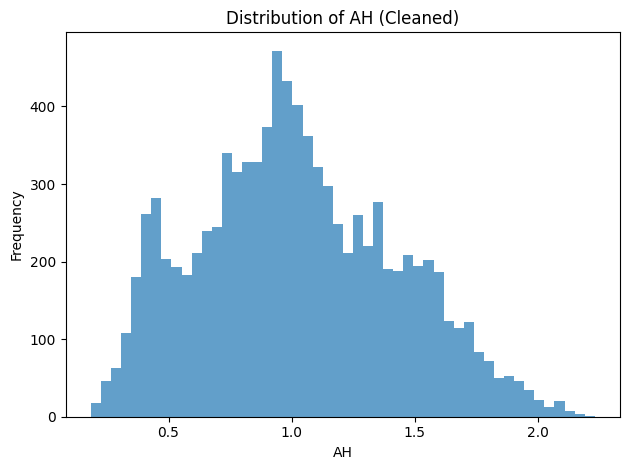

In [36]:
# ---------- 5. Distribution plots for key variables ----------
pollutants = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
met_vars   = ["T", "RH", "AH"]

for col in pollutants + met_vars:
    if col in df.columns:
        plt.figure()
        df[col].plot(kind="hist", bins=50, alpha=0.7)
        plt.title(f"Distribution of {col} (Cleaned)")
        plt.xlabel(col); plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

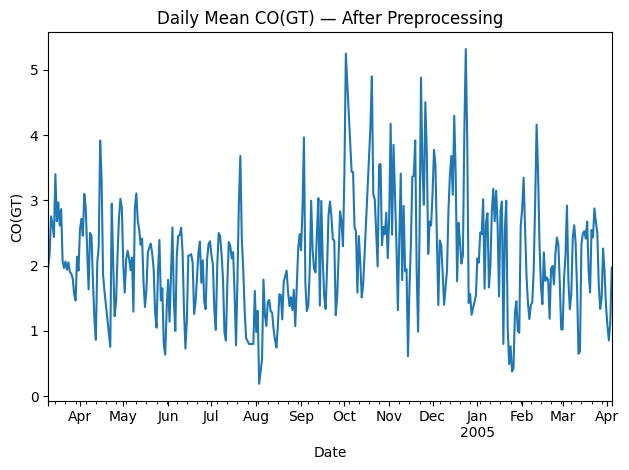

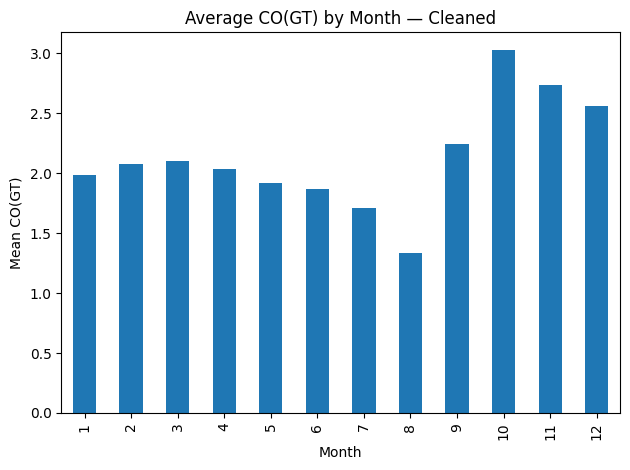

In [37]:
# ---------- 6. Daily & monthly trends for CO(GT) ----------
if "CO(GT)" in df.columns:
    daily_co = df.set_index("timestamp")["CO(GT)"].resample("D").mean()
    plt.figure()
    daily_co.plot(title="Daily Mean CO(GT) — After Preprocessing")
    plt.xlabel("Date"); plt.ylabel("CO(GT)")
    plt.tight_layout(); plt.show()

    monthly_co = df.groupby(df["timestamp"].dt.month)["CO(GT)"].mean()
    plt.figure()
    monthly_co.plot(kind="bar", title="Average CO(GT) by Month — Cleaned")
    plt.xlabel("Month"); plt.ylabel("Mean CO(GT)")
    plt.tight_layout(); plt.show()

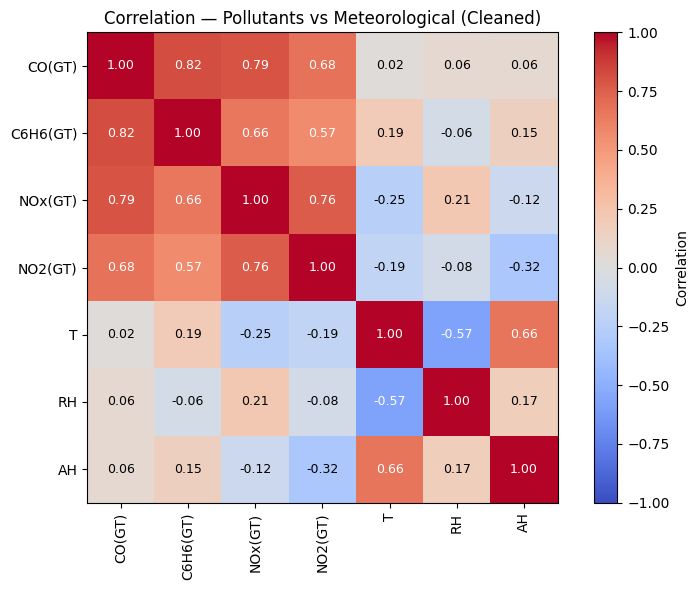

In [38]:
# ---------- 7A. Correlation — GT pollutants + meteorological ----------
chem_cols = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
met_cols  = ["T", "RH", "AH"]
corr_cols = [c for c in chem_cols + met_cols if c in df.columns]
corr = df[corr_cols].corr()

plt.figure(figsize=(8,6))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i,j]
        plt.text(j,i,f"{v:.2f}", ha="center", va="center",
                 color="black" if abs(v)<0.5 else "white", fontsize=9)
plt.xticks(np.arange(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(np.arange(len(corr_cols)), corr_cols)
plt.title("Correlation — Pollutants vs Meteorological (Cleaned)")
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()

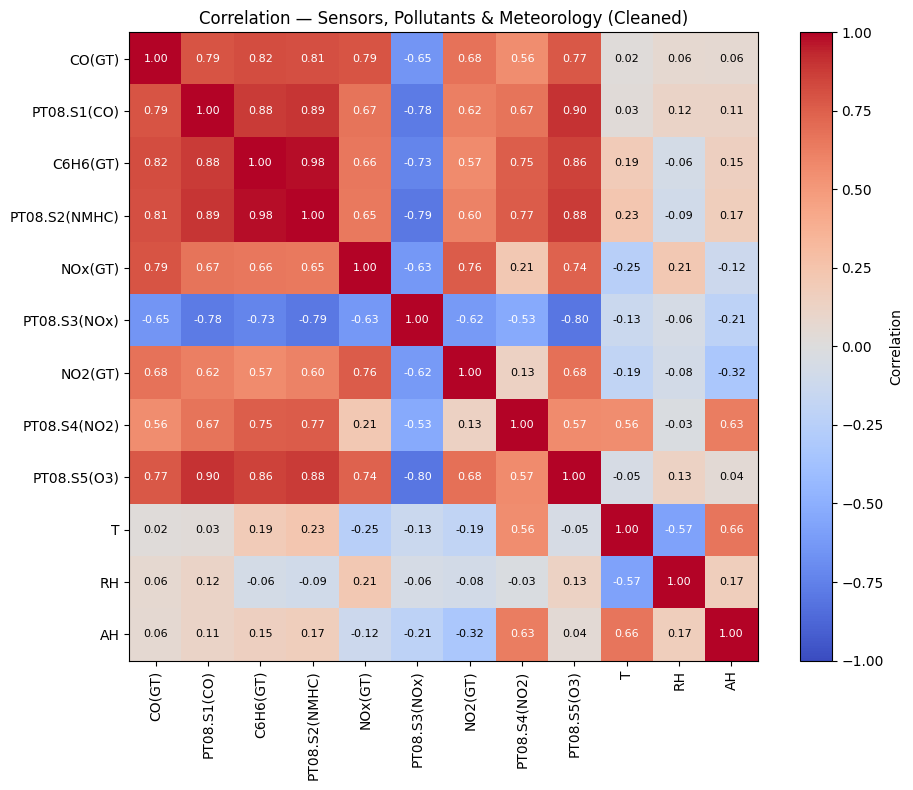

In [39]:
# ---------- 7B. Correlation — GT + PT08 sensors + meteorological ----------
cand = [c for c in df.columns if "(GT)" in c or c.startswith("PT08.") or c in {"T","RH","AH"}]
df_num = df[cand].apply(pd.to_numeric, errors="coerce")
keep = [c for c in df_num.columns if df_num[c].notna().any()]
corr_full = df_num[keep].corr()

plt.figure(figsize=(10,8))
im = plt.imshow(corr_full, cmap="coolwarm", vmin=-1, vmax=1)
for i in range(len(keep)):
    for j in range(len(keep)):
        val = corr_full.iloc[i,j]
        plt.text(j,i,f"{val:.2f}",
                 ha="center",va="center",
                 color="black" if abs(val)<0.5 else "white",
                 fontsize=8)
plt.xticks(np.arange(len(keep)), keep, rotation=90)
plt.yticks(np.arange(len(keep)), keep)
plt.title("Correlation — Sensors, Pollutants & Meteorology (Cleaned)")
plt.colorbar(im, label="Correlation")
plt.tight_layout(); plt.show()